In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.stats import gaussian_kde
from scipy.linalg import sqrtm
import os, sys, random

import seaborn as sns
sns.set_theme(style='ticks', palette='pastel')

def seed_everything(seed=42):
    np.random.seed(seed)
    import torch; torch.manual_seed(seed)
    random.seed(seed)

## Gaussian → Gaussian Mixture: Model Comparison

Side-by-side comparison of **Target**, **OFM**, **DM**, and **DM with Friction (DMF)**.

In [2]:
import torch
from OFM.ofmsrc.distributions import Sampler, StandardNormalSampler

DEVICE = 'cpu'

class GaussianMixture(Sampler):
    def __init__(self, parameters, device='cpu'):
        super().__init__(device=device)
        self.dim   = len(parameters[0]['mean'])
        self.means = torch.tensor([p['mean'] for p in parameters], dtype=torch.float32, device=device)
        self.stds  = torch.tensor([p['std']  for p in parameters], dtype=torch.float32, device=device)
        self.K = len(parameters)

    def sample(self, batch_size=10):
        idx   = torch.randint(0, self.K, (batch_size,), device=self.device)
        means = self.means[idx]
        stds  = self.stds[idx]
        return means + stds * torch.randn(batch_size, self.dim, device=self.device)

    def sample_np(self, n):
        return self.sample(n).cpu().numpy()

parameters = [
    {'mean': [0, 0],  'std': [1,   1  ]},
    {'mean': [3, 2],  'std': [1, 1]},
]
mixture        = GaussianMixture(parameters, device=DEVICE)
source_sampler = StandardNormalSampler(device=DEVICE)

In [3]:
# ── Load saved generated + real samples ───────────────────────────────────────
EXP_DIRS = {
    'OFM' : './gaumix_ofm',
    'DM'  : './gaumix_dm',
    'DMF' : './gaumix_dmf',
}

gen_samples  = {}
real_samples = {}

for name, exp_dir in EXP_DIRS.items():
    gen_path  = os.path.join(exp_dir, 'generated_samples.npy')
    real_path = os.path.join(exp_dir, 'real_samples.npy')
    if os.path.exists(gen_path) and os.path.exists(real_path):
        gen_samples[name]  = np.load(gen_path)
        real_samples[name] = np.load(real_path)
        print(f'{name:6s}: loaded {len(gen_samples[name])} gen + {len(real_samples[name])} real from {exp_dir}')
    else:
        missing = []
        if not os.path.exists(gen_path):  missing.append('generated_samples.npy')
        if not os.path.exists(real_path): missing.append('real_samples.npy')
        print(f'{name:6s}: NOT FOUND — {", ".join(missing)} in {exp_dir}')

# Use the first available real_samples for the Target display panel
_ref = next(iter(real_samples.values())) if real_samples else np.zeros((0, 2))
samples = {'Target': _ref, **gen_samples}

OFM   : loaded 10000 gen + 10000 real from ./gaumix_ofm
DM    : loaded 10000 gen + 10000 real from ./gaumix_dm
DMF   : loaded 10000 gen + 10000 real from ./gaumix_dmf


In [4]:
# ── Fréchet Distance — computed from the exact arrays saved by each notebook ──
from scipy.linalg import sqrtm

def frechet_distance(real_samples, gen_samples):
    mu_r = real_samples.mean(axis=0)
    mu_g = gen_samples.mean(axis=0)
    sigma_r = np.cov(real_samples, rowvar=False)
    sigma_g = np.cov(gen_samples, rowvar=False)
    diff = mu_r - mu_g
    covmean = sqrtm(sigma_r @ sigma_g)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(diff @ diff + np.trace(sigma_r + sigma_g - 2 * covmean))

fd_scores = {}
for name in ['OFM', 'DM', 'DMF']:
    if name in gen_samples and name in real_samples:
        fd_scores[name] = frechet_distance(real_samples[name], gen_samples[name])
        print(f'FD  {name:4s} = {fd_scores[name]:.6f}')
    else:
        fd_scores[name] = float('nan')
        print(f'FD  {name:4s} = N/A (samples not loaded)')

FD  OFM  = 0.008697
FD  DM   = 0.079089
FD  DMF  = 0.002893


Saved  ./comparison_gaumix.pdf


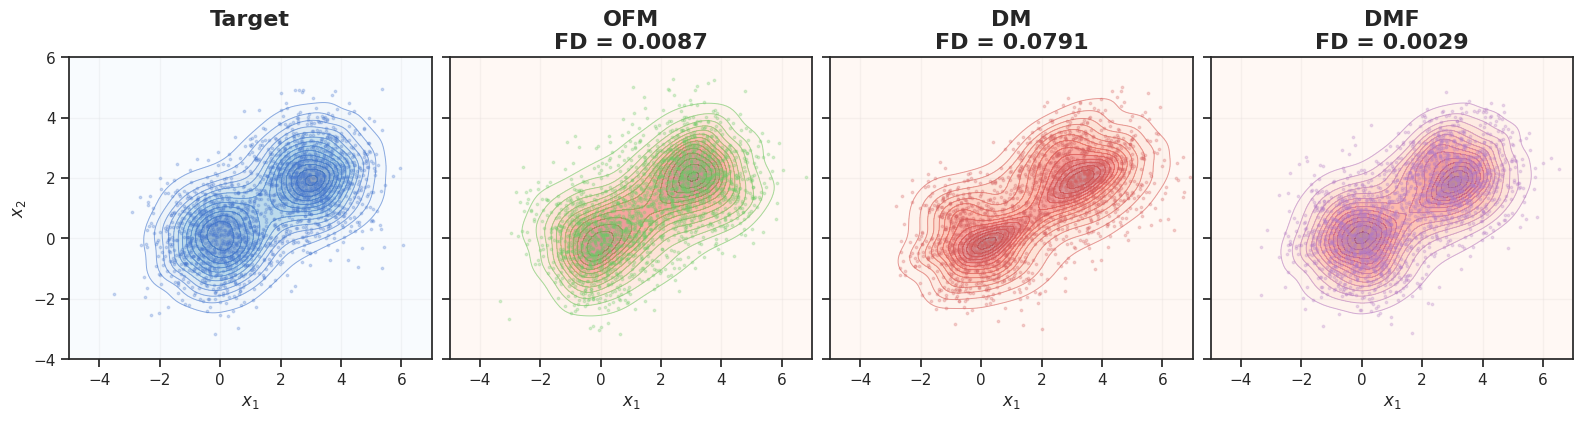

In [5]:
# ── Side-by-side comparison plot ──────────────────────────────────────────────
np.random.seed(42)

PANEL_ORDER = ['Target', 'OFM', 'DM', 'DMF']
COLORS      = {'Target': '#4878CF', 'OFM': '#6ACC65', 'DM': '#D65F5F', 'DMF': '#B47CC7'}

xlim = (-5, 7)
ylim = (-4, 6)
grid_res = 120j
xx, yy   = np.mgrid[xlim[0]:xlim[1]:grid_res, ylim[0]:ylim[1]:grid_res]
grid_pts = np.vstack([xx.ravel(), yy.ravel()])

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
fig.subplots_adjust(wspace=0.05, left=0.04, right=0.98, top=0.88, bottom=0.1)

for ax, name in zip(axes, PANEL_ORDER):
    if name not in samples:
        ax.text(0.5, 0.5, f'{name}\nnot found', ha='center', va='center',
                transform=ax.transAxes, fontsize=12)
        ax.set_title(name)
        continue

    pts   = samples[name]
    color = COLORS[name]

    # KDE density
    try:
        kde     = gaussian_kde(pts.T, bw_method=0.25)
        density = kde(grid_pts).reshape(xx.shape)
        ax.contourf(xx, yy, density, levels=14, cmap='Blues' if name == 'Target' else 'Reds',
                    alpha=0.45)
        ax.contour (xx, yy, density, levels=14, colors=color, alpha=0.6, linewidths=0.7)
    except Exception:
        pass

    # Scatter (subsample for speed)
    idx = np.random.choice(len(pts), size=min(2000, len(pts)), replace=False)
    ax.scatter(pts[idx, 0], pts[idx, 1], s=3, alpha=0.25, color=color, rasterized=True)

    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)

    fd_str = f'FD = {fd_scores[name]:.4f}' if name in fd_scores else ''
    ax.set_title(f'{name}\n{fd_str}', fontsize=16, fontweight='bold')
    ax.set_xlabel('$x_1$')

axes[0].set_ylabel('$x_2$')
# fig.suptitle('Gaussian  →  Gaussian Mixture  |  Model comparison', fontsize=13)

out_base = './comparison_gaumix'
fig.savefig(out_base + '.pdf', bbox_inches='tight')
print(f'Saved  {out_base}.pdf')
plt.show()